In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

df = pd.read_csv("../data/telco_clean.csv")
df.shape

(7043, 20)

Overall churn rate: 26.5%


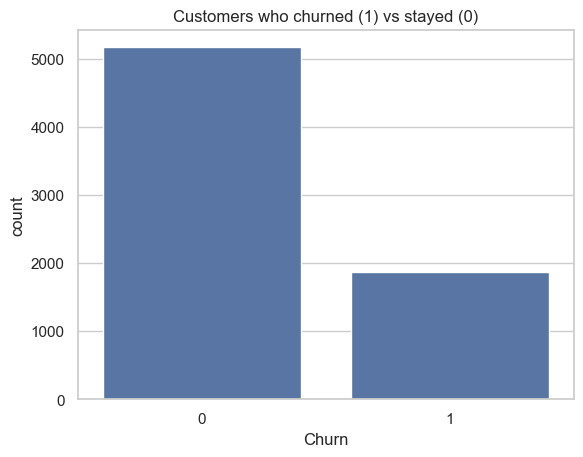

In [2]:
churn_rate = df["Churn"].mean()
print(f"Overall churn rate: {churn_rate:.1%}")

sns.countplot(x="Churn", data=df)
plt.title("Customers who churned (1) vs stayed (0)")
plt.show()

In [3]:
def churn_by(col):
    rate = df.groupby(col)["Churn"].mean().sort_values(ascending=False)
    print((rate * 100).round(1).astype(str) + "%")
    sns.barplot(x=rate.index, y=rate.values)
    plt.axhline(churn_rate, color="red", linestyle="--", label="Overall churn rate")
    plt.ylabel("Churn rate")
    plt.title(f"Churn rate by {col}")
    plt.xticks(rotation=20)
    plt.legend()
    plt.show()

Contract
Month-to-month    42.7%
One year          11.3%
Two year           2.8%
Name: Churn, dtype: object


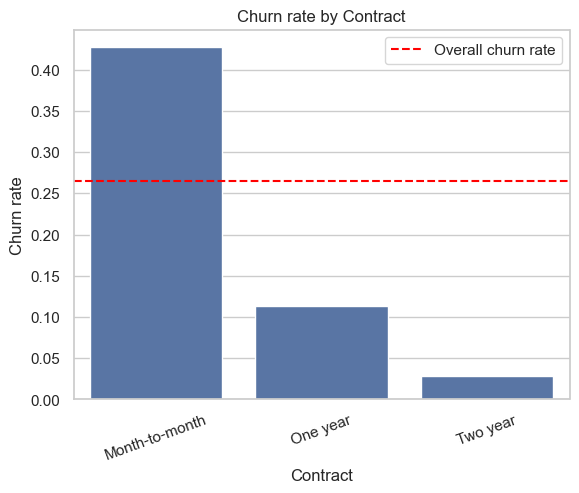

In [4]:
churn_by("Contract")

InternetService
Fiber optic    41.9%
DSL            19.0%
No              7.4%
Name: Churn, dtype: object


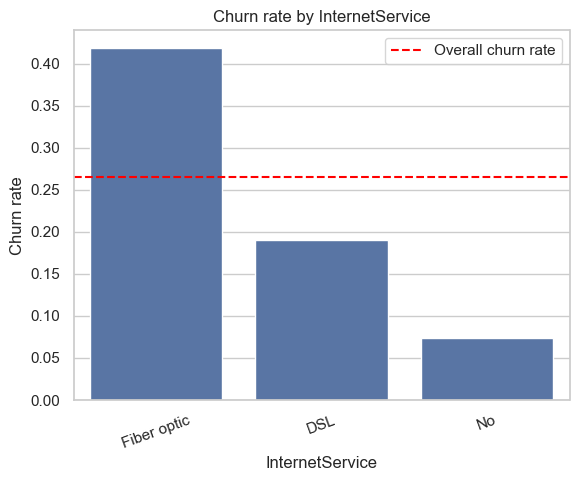

In [5]:
churn_by("InternetService")

PaymentMethod
Electronic check             45.3%
Mailed check                 19.1%
Bank transfer (automatic)    16.7%
Credit card (automatic)      15.2%
Name: Churn, dtype: object


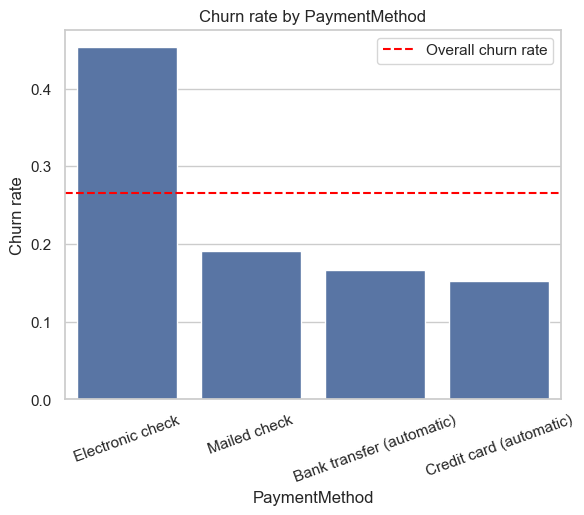

In [6]:
churn_by("PaymentMethod")

TechSupport
No     31.2%
Yes    15.2%
Name: Churn, dtype: object


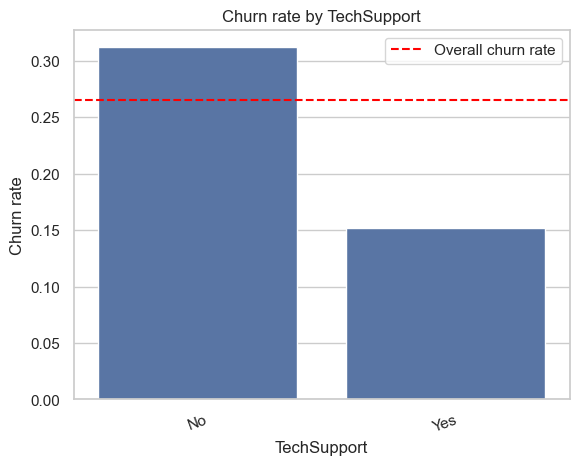

OnlineSecurity
No     31.3%
Yes    14.6%
Name: Churn, dtype: object


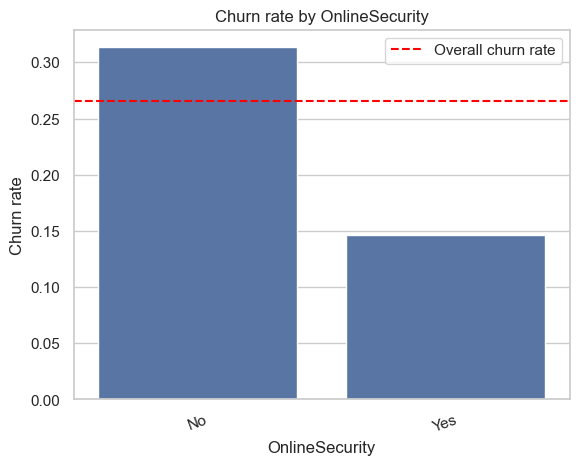

In [7]:
churn_by("TechSupport")
churn_by("OnlineSecurity")

SeniorCitizen
1    41.7%
0    23.6%
Name: Churn, dtype: object


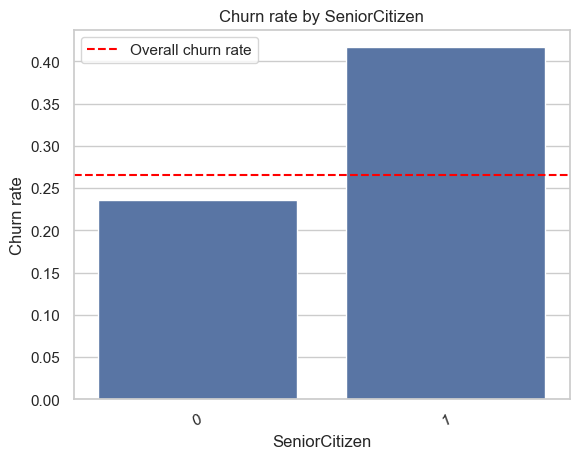

Partner
No     33.0%
Yes    19.7%
Name: Churn, dtype: object


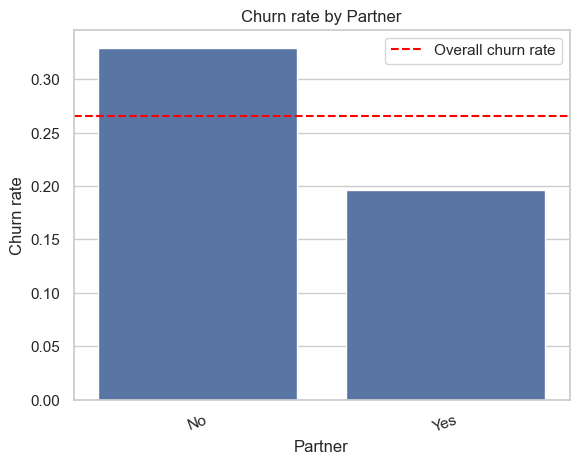

Dependents
No     31.3%
Yes    15.5%
Name: Churn, dtype: object


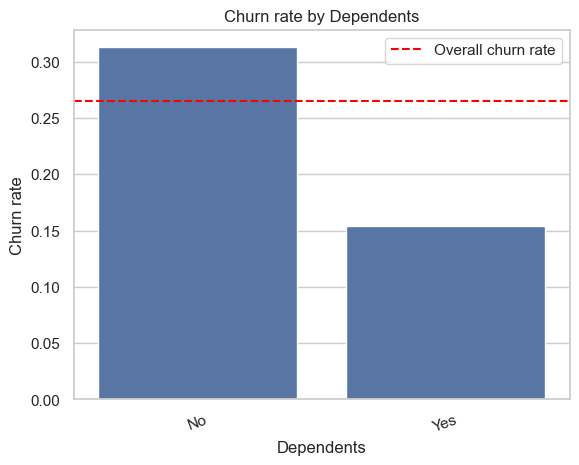

In [8]:
churn_by("SeniorCitizen")
churn_by("Partner")
churn_by("Dependents")

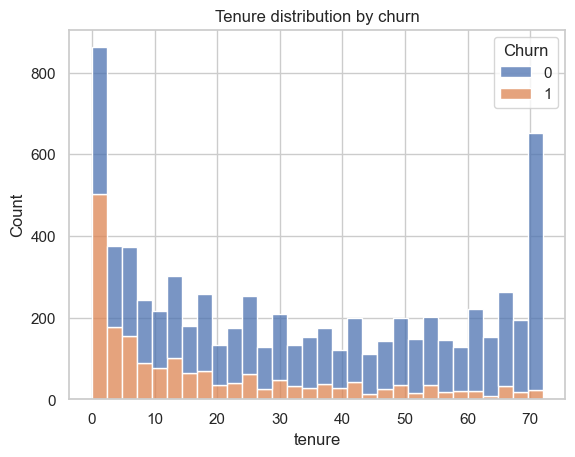

Churn
0    38.0
1    10.0
Name: tenure, dtype: float64


In [9]:
sns.histplot(data=df, x="tenure", hue="Churn", bins=30, multiple="stack")
plt.title("Tenure distribution by churn")
plt.show()

print(df.groupby("Churn")["tenure"].median())

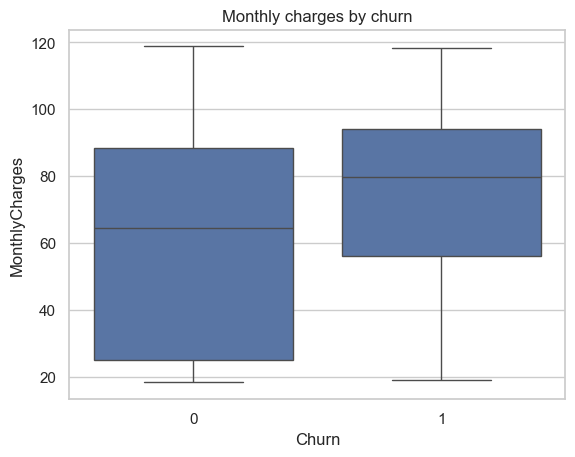

Churn
0    61.3
1    74.4
Name: MonthlyCharges, dtype: float64


In [10]:
sns.boxplot(x="Churn", y="MonthlyCharges", data=df)
plt.title("Monthly charges by churn")
plt.show()

print(df.groupby("Churn")["MonthlyCharges"].mean().round(1))

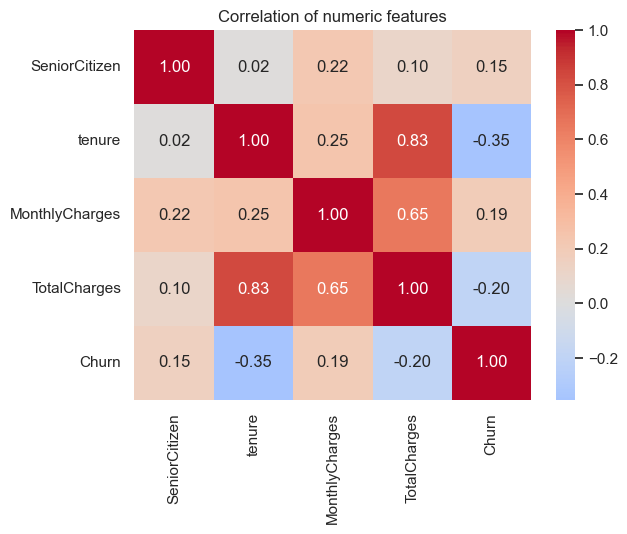

In [11]:
num_cols = ["SeniorCitizen", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]
corr = df[num_cols].corr()

sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation of numeric features")
plt.show()

## Key findings
- Overall churn rate is about 26.5%.
- Month-to-month contracts have by far the highest churn.
- Churn is concentrated in the first months of tenure.
- Fiber optic and electronic check customers churn more.
- Customers with tech support or online security churn less.
- Higher monthly charges are linked to higher churn.